# Partie 1 - Découverte et préparation des données

**Objectif du projet :** identifier l'utilisateur de Copilote (logiciel Infologic) à partir des traces d'une session.
C'est une **classification supervisée multi-classe** : chaque session du train est étiquetée par son utilisateur (`util`), il faut prédire l'utilisateur des 324 sessions du test.

## 1. Importation des bibliothèques

In [1]:
from pathlib import Path
import gzip

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid')


## 2. Chargement des données brutes

Les fichiers sont cherchés dans `Data/`, `data/` ou à la racine du projet, compressés (`train.csv.GZ`, tels que téléchargés depuis Kaggle, lus directement avec `gzip`) ou non (`train.csv`).

Chaque ligne est une session, avec un nombre de champs variable (séparés par des virgules) :
- **train** : `utilisateur, navigateur, action_1, action_2, ...`
- **test** : `navigateur, action_1, action_2, ...` (pas d'utilisateur, c'est ce qu'on doit prédire)

Comme les sessions n'ont pas la même longueur, on lit le fichier ligne par ligne (comme conseillé dans les indications) plutôt qu'avec `pd.read_csv`, qui créerait plus de 14 000 colonnes presque toutes vides.

In [2]:
# Racine du projet (le notebook est dans travail_partie_1/)
RACINE = Path.cwd().parent


def trouver_fichier(nom):
    """Chemin de `nom`.csv ou `nom`.csv.GZ, cherché dans Data/, data/ puis à la racine du projet."""
    for dossier in [RACINE / 'Data', RACINE / 'data', RACINE]:
        for suffixe in ['.csv', '.csv.GZ', '.csv.gz']:
            chemin = dossier / f'{nom}{suffixe}'
            if chemin.exists():
                return chemin
    raise FileNotFoundError(f'{nom}.csv introuvable dans {RACINE}/Data, {RACINE}/data ou {RACINE}')


def lire_lignes(chemin):
    """Lignes d'un fichier texte, compressé (.gz) ou non."""
    ouvrir = gzip.open if str(chemin).lower().endswith('.gz') else open
    with ouvrir(chemin, 'rt', encoding='utf-8') as f:
        return f.read().splitlines()


train_path = trouver_fichier('train')
test_path = trouver_fichier('test')
print('Données lues dans :', train_path.parent)

In [3]:
train_lines = lire_lignes(train_path)
test_lines = lire_lignes(test_path)

print(f'train : {len(train_lines)} sessions')
print(f'test  : {len(test_lines)} sessions')
print()
print('Début de la 1re session du train :')
print(train_lines[0][:300])

train : 3279 sessions
test  : 324 sessions

Début de la 1re session du train :
nuh,Firefox,Création d'un écran(infologic.core.accueil.AccueilController),Affichage d'une dialogue,Exécution d'un bouton,Fermeture d'une dialogue,Affichage d'une dialogue,Exécution d'un bouton,Fermeture d'une dialogue,Création d'un écran(infologic.core.gui.controllers.nested.InputFormNestedWindow),t


On découpe chaque ligne sur la virgule (le délimiteur) et on range le résultat dans un DataFrame à 3 colonnes : `util` (la cible), `navigateur`, et `actions` (la **liste** des événements de la session, dans l'ordre).

In [4]:
def decouper_session(ligne, avec_util):
    champs = ligne.split(',')
    if avec_util:
        return {'util': champs[0], 'navigateur': champs[1], 'actions': champs[2:]}
    return {'navigateur': champs[0], 'actions': champs[1:]}


train = pd.DataFrame([decouper_session(l, avec_util=True) for l in train_lines])
test = pd.DataFrame([decouper_session(l, avec_util=False) for l in test_lines])

print(f'Train : {train.shape[0]} sessions, {train["util"].nunique()} utilisateurs')
print(f'Test  : {test.shape[0]} sessions')
display(train.head())

Train : 3279 sessions, 247 utilisateurs
Test  : 324 sessions


,util,navigateur,actions
0,nuh,Firefox,[Création d'un écran(infologic.core.accueil.Ac...
1,muz,Google Chrome,[Création d'un écran(infologic.core.gui.contro...
2,zrx,Microsoft Edge,[Affichage d'une dialogue(infologic.core.gui.c...
3,pou,Firefox,[Création d'un écran(infologic.core.gui.contro...
4,ald,Google Chrome,[Affichage d'une dialogue(infologic.acti.modul...


In [5]:
train.loc[0, 'actions'][:30]

["Création d'un écran(infologic.core.accueil.AccueilController)",
 "Affichage d'une dialogue",
 "Exécution d'un bouton",
 "Fermeture d'une dialogue",
 "Affichage d'une dialogue",
 "Exécution d'un bouton",
 "Fermeture d'une dialogue",
 "Création d'un écran(infologic.core.gui.controllers.nested.InputFormNestedWindow)",
 't5',
 "Exécution d'un bouton(MAINT)",
 "Affichage d'une dialogue",
 "Fermeture d'une dialogue",
 'Double-clic',
 "Exécution d'un bouton",
 "Lancement d'une stat(infologic.core.gui.controllers.nested.homeview.InputFormHomeView)",
 "Affichage d'un toast",
 "Lancement d'une stat(infologic.core.gui.controllers.nested.homeview.InputFormHomeView)",
 't10',
 "Affichage d'une dialogue(MAINT)",
 "Exécution d'un bouton",
 "Fermeture d'une dialogue",
 't15',
 'Double-clic',
 "Lancement d'une action générique",
 "Affichage d'une dialogue",
 "Affichage d'un toast",
 'Filtrage / Tri',
 "Exécution d'un bouton",
 "Fermeture d'une dialogue",
 "Création d'un écran"]

In [6]:
len(train.loc[100, 'actions']) 

657

In [7]:
train['util'].value_counts().head()

util
skm    75
slq    71
cjr    46
flj    42
hjs    37
Name: count, dtype: int64

## 3. Sessions et actions par utilisateur

Dans la liste `actions`, les éléments `t5`, `t10`, `t15`… ne sont pas des actions : ce sont des **repères de temps** (un toutes les 5 secondes). On les exclut pour compter les vraies actions de chaque session.

In [8]:
import re

est_repere_temps = re.compile(r't\d+')  # t5, t10, t1520...

def compter_actions(evenements):
    return sum(1 for e in evenements if not est_repere_temps.fullmatch(e))

train['nb_actions'] = train['actions'].apply(compter_actions)
train[['util', 'navigateur', 'nb_actions']].head()

,util,navigateur,nb_actions
0,nuh,Firefox,2514
1,muz,Google Chrome,90
2,zrx,Microsoft Edge,608
3,pou,Firefox,886
4,ald,Google Chrome,173


On regroupe ensuite les sessions par utilisateur (`groupby`) pour obtenir, pour chacun :
- `nb_sessions` : nombre de sessions dans le train ;
- `nb_actions_total` : somme des actions sur toutes ses sessions ;
- `nb_actions_moyen` : nombre moyen d'actions par session.

In [9]:
par_util = train.groupby('util').agg(
    nb_sessions=('util', 'size'),
    nb_actions_total=('nb_actions', 'sum'),
    nb_actions_moyen=('nb_actions', 'mean'),
).round(0)

print('Top 10 - utilisateurs avec le plus de sessions')
display(par_util.sort_values('nb_sessions', ascending=False).head(10))

print('Top 10 - utilisateurs avec le plus d actions au total')
display(par_util.sort_values('nb_actions_total', ascending=False).head(10))

Top 10 - utilisateurs avec le plus de sessions


,nb_sessions,nb_actions_total,nb_actions_moyen
util,,,
skm,75,19901,265.0
slq,71,14880,210.0
cjr,46,19172,417.0
flj,42,13753,327.0
hjs,37,15974,432.0
vfo,35,26635,761.0
nqg,34,10151,299.0
shh,34,9286,273.0
fwf,33,5723,173.0


Top 10 - utilisateurs avec le plus d actions au total


,nb_sessions,nb_actions_total,nb_actions_moyen
util,,,
zct,14,38815,2772.0
fxg,5,33646,6729.0
fjb,11,32943,2995.0
fvc,29,30898,1065.0
bgn,27,30202,1119.0
wvy,12,29402,2450.0
nwt,20,27916,1396.0
opp,24,26770,1115.0
vfo,35,26635,761.0


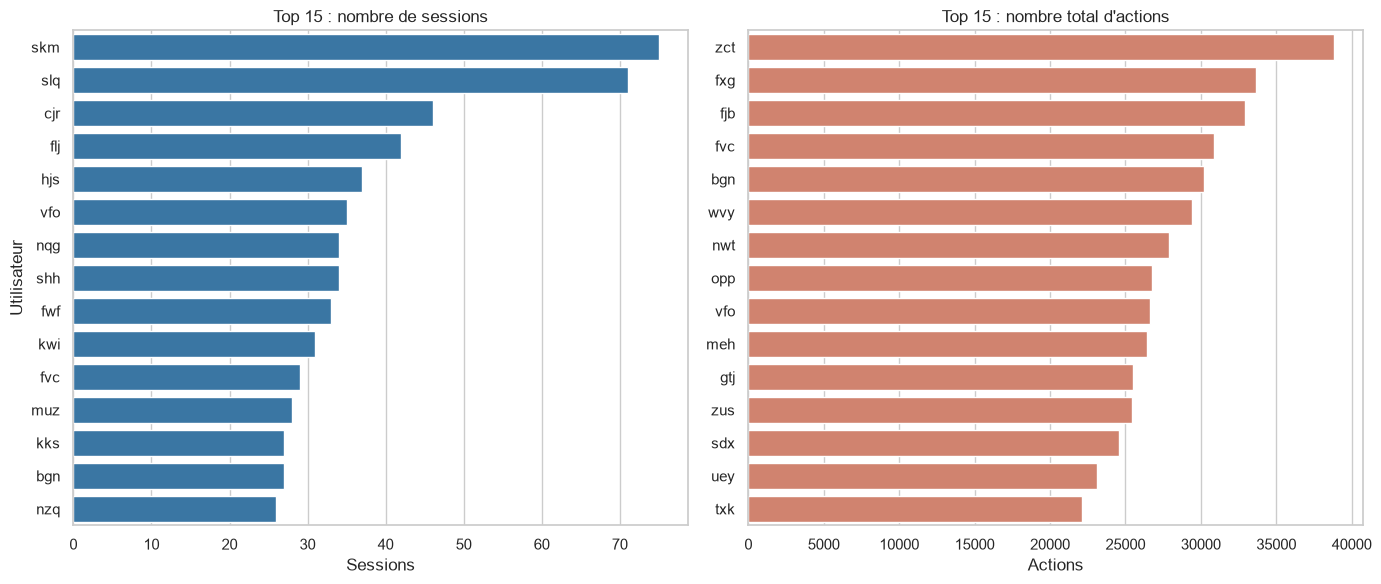

In [10]:
top_sessions = par_util['nb_sessions'].sort_values(ascending=False).head(15)
top_actions = par_util['nb_actions_total'].sort_values(ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(x=top_sessions.values, y=top_sessions.index, ax=axes[0], color='#2878b5')
axes[0].set_title('Top 15 : nombre de sessions')
axes[0].set_xlabel('Sessions')
axes[0].set_ylabel('Utilisateur')

sns.barplot(x=top_actions.values, y=top_actions.index, ax=axes[1], color='#e07a5f')
axes[1].set_title("Top 15 : nombre total d'actions")
axes[1].set_xlabel('Actions')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

In [11]:
# Vue d'ensemble sur les 247 utilisateurs
par_util.describe().round(0)

,nb_sessions,nb_actions_total,nb_actions_moyen
count,247.0,247.0,247.0
mean,13.0,9191.0,790.0
std,9.0,6990.0,691.0
min,4.0,435.0,91.0
25%,7.0,4480.0,364.0
50%,12.0,7607.0,595.0
75%,16.0,11647.0,1006.0
max,75.0,38815.0,6729.0


## 4. La dimension temporelle des sessions

Les repères `tXX` indiquent le temps écoulé dans la session, **en secondes**, par pas de 5 s (`t5`, `t10`, `t15`…). Toutes les actions situées entre `t10` et `t15` ont eu lieu dans cette fenêtre de 5 secondes.

À partir de ces repères, on peut mesurer pour chaque session :
- **la durée** : le dernier repère atteint ;
- **la fréquence** : le nombre d'actions par minute (vitesse de travail) ;
- **le rythme** : comment les actions se répartissent dans les fenêtres de 5 s (régulier, ou par rafales).

Les données ne contiennent **aucune date ni heure** : on ne sait pas à quel moment de la journée ou de la semaine une session a eu lieu. La « période » au sens calendrier n'est donc pas mesurable ici.

In [12]:
def profil_temporel(evenements):
    """Durée, nombre d'actions et répartition des actions par fenêtre de 5 s."""
    actions_par_fenetre = {}
    temps_courant = 0
    for e in evenements:
        if est_repere_temps.fullmatch(e):
            temps_courant = int(e[1:])          # 't15' -> 15
        else:
            actions_par_fenetre[temps_courant] = actions_par_fenetre.get(temps_courant, 0) + 1
    comptes = pd.Series(actions_par_fenetre, dtype=float)
    return pd.Series({
        'duree_s': temps_courant,
        'actions_par_fenetre_moy': comptes.mean(),
        'actions_par_fenetre_max': comptes.max(),
        'actions_par_fenetre_std': comptes.std(),
    })


temps = train['actions'].apply(profil_temporel)
train = pd.concat([train.drop(columns=temps.columns, errors='ignore'), temps], axis=1)

# Fréquence : actions par minute (durée minimale de 5 s pour éviter une division par 0)
train['actions_par_min'] = train['nb_actions'] / (train['duree_s'].clip(lower=5) / 60)

train[['util', 'nb_actions', 'duree_s', 'actions_par_min', 'actions_par_fenetre_max']].head()

,util,nb_actions,duree_s,actions_par_min,actions_par_fenetre_max
0,nuh,2514,2905.0,51.924269,22.0
1,muz,90,230.0,23.478261,6.0
2,zrx,608,750.0,48.640000,22.0
3,pou,886,1445.0,36.788927,22.0
4,ald,173,275.0,37.745455,15.0


In [13]:
train[['duree_s', 'nb_actions', 'actions_par_min', 'actions_par_fenetre_moy', 'actions_par_fenetre_max']].describe().round(1)

,duree_s,nb_actions,actions_par_min,actions_par_fenetre_moy,actions_par_fenetre_max
count,3279.0,3279.0,3279.0,3278.0,3278.0
mean,751.5,692.4,56.3,4.6,32.5
std,1006.3,1005.9,23.3,1.7,49.7
min,5.0,0.0,0.0,1.0,1.0
25%,185.0,153.0,44.0,3.6,17.0
50%,395.0,340.0,52.8,4.3,25.0
75%,945.0,818.5,64.0,5.2,38.0
max,11790.0,11977.0,556.0,34.8,1859.0


### 4.1 Durée des sessions

Les durées sont très étalées (quelques secondes à plus de 3 heures). On utilise une **échelle logarithmique** sur l'axe horizontal pour voir à la fois les sessions courtes et les très longues.

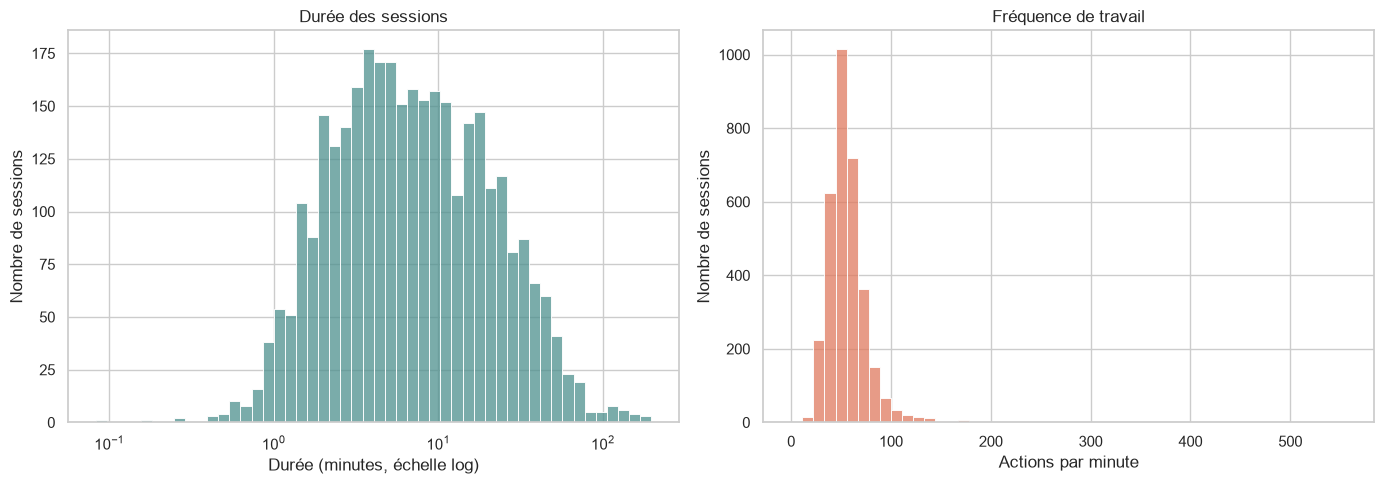

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(train['duree_s'] / 60, bins=50, log_scale=True, ax=axes[0], color='#4d908e')
axes[0].set_title('Durée des sessions')
axes[0].set_xlabel('Durée (minutes, échelle log)')
axes[0].set_ylabel('Nombre de sessions')

sns.histplot(train['actions_par_min'], bins=50, ax=axes[1], color='#e07a5f')
axes[1].set_title('Fréquence de travail')
axes[1].set_xlabel('Actions par minute')
axes[1].set_ylabel('Nombre de sessions')

plt.tight_layout()
plt.show()

### 4.2 Le temps distingue-t-il les utilisateurs ?

Question clé pour la classification : un même utilisateur a-t-il des sessions **semblables entre elles** et **différentes de celles des autres** ? On compare la distribution de ces variables pour les 10 utilisateurs qui ont le plus de sessions (un boxplot par utilisateur).

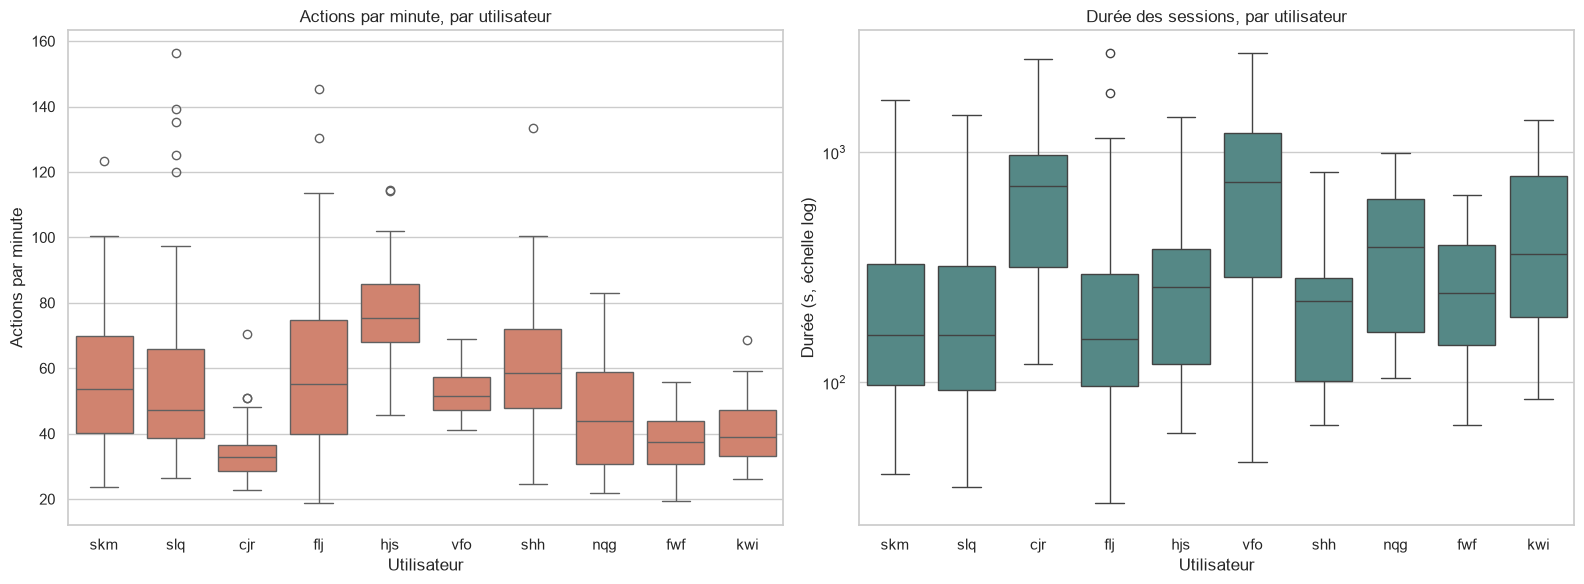

In [15]:
top10 = train['util'].value_counts().head(10).index
extrait = train[train['util'].isin(top10)]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(data=extrait, x='util', y='actions_par_min', order=top10, ax=axes[0], color='#e07a5f')
axes[0].set_title('Actions par minute, par utilisateur')
axes[0].set_xlabel('Utilisateur')
axes[0].set_ylabel('Actions par minute')

sns.boxplot(data=extrait, x='util', y='duree_s', order=top10, ax=axes[1], color='#4d908e', log_scale=True)
axes[1].set_title('Durée des sessions, par utilisateur')
axes[1].set_xlabel('Utilisateur')
axes[1].set_ylabel('Durée (s, échelle log)')

plt.tight_layout()
plt.show()

In [16]:
# Résumé par utilisateur : valeurs typiques (médianes) de ses sessions
profil_util = train.groupby('util').agg(
    nb_sessions=('util', 'size'),
    duree_mediane_min=('duree_s', lambda d: d.median() / 60),
    actions_par_min_median=('actions_par_min', 'median'),
).round(1)

print('Les plus rapides (actions par minute)')
display(profil_util.sort_values('actions_par_min_median', ascending=False).head(5))
print('Les plus lents')
display(profil_util.sort_values('actions_par_min_median').head(5))
print('Les sessions les plus longues')
display(profil_util.sort_values('duree_mediane_min', ascending=False).head(5))

Les plus rapides (actions par minute)


,nb_sessions,duree_mediane_min,actions_par_min_median
util,,,
sii,19,6.2,87.6
qof,16,10.0,87.2
nyk,15,3.8,83.4
cje,8,2.4,81.3
sdx,11,28.1,76.9


Les plus lents


,nb_sessions,duree_mediane_min,actions_par_min_median
util,,,
zll,4,5.1,28.5
tdk,14,4.9,30.2
lnq,5,16.8,31.8
cjr,46,11.8,32.8
hzx,20,4.4,34.2


Les sessions les plus longues


,nb_sessions,duree_mediane_min,actions_par_min_median
util,,,
fxg,5,71.8,76.0
nsf,6,58.8,42.6
npo,6,42.0,65.8
ckl,6,37.4,63.2
cum,5,32.4,63.0


## 5. Ce que fait l'utilisateur : navigateur, types d'actions, écrans, chaînes

### Anatomie d'une action

Une action peut porter jusqu'à 4 informations, repérées par des délimiteurs :

```
Exécution d'un bouton(infologic.orga.FicheForm)<DEF_03/24>$JCP$1
└──── type d'action ──┘└──────── écran ────────┘└─ conf ─┘└chaîne┘└ suffixe
```

| Élément | Délimiteur | Exemple | Signification |
|---|---|---|---|
| type d'action | (début) | `Exécution d'un bouton` | le geste fait par l'utilisateur |
| écran | `( … )` | `infologic.orga.FicheForm` | la fenêtre du logiciel concernée |
| configuration d'écran | `< … >` | `DEF_03/24` | la variante / le paramétrage de l'écran |
| chaîne | `$ … $` | `JCP` | la catégorie de fiche travaillée |
| suffixe `1` | à la fin | `Saisie dans un champ1` | sens non documenté ici, à vérifier sur Kaggle |

Seule une partie des actions porte un écran, une configuration ou une chaîne : les autres n'ont que le type.

In [17]:
motif_ecran = re.compile(r'\((.*?)\)')
motif_conf = re.compile(r'<(.*?)>')
motif_chaine = re.compile(r'\$(.*?)\$')
motif_type = re.compile(r'[(<$]')  # le type s'arrête au premier délimiteur


def decomposer_action(action):
    """Découpe une action en ses composantes (None si absente)."""
    ecran = motif_ecran.search(action)
    conf = motif_conf.search(action)
    chaine = motif_chaine.search(action)
    return {
        'type': motif_type.split(action)[0].removesuffix('1'),
        'ecran': ecran.group(1) if ecran else None,
        'conf': conf.group(1) if conf else None,
        'chaine': chaine.group(1) if chaine else None,
        'suffixe_1': action.endswith('1'),
    }


# Vérification sur quelques exemples
for exemple in ["Exécution d'un bouton<DEF_03/24>$JCP$",
                "Création d'un écran(infologic.core.accueil.AccueilController)",
                'Saisie dans un champ1']:
    print(exemple, '->', decomposer_action(exemple))

Exécution d'un bouton<DEF_03/24>$JCP$ -> {'type': "Exécution d'un bouton", 'ecran': None, 'conf': 'DEF_03/24', 'chaine': 'JCP', 'suffixe_1': False}
Création d'un écran(infologic.core.accueil.AccueilController) -> {'type': "Création d'un écran", 'ecran': 'infologic.core.accueil.AccueilController', 'conf': None, 'chaine': None, 'suffixe_1': False}
Saisie dans un champ1 -> {'type': 'Saisie dans un champ', 'ecran': None, 'conf': None, 'chaine': None, 'suffixe_1': True}


On construit une table « longue » `evenements` : **une ligne par action** (2,3 millions de lignes), avec le numéro de session, l'utilisateur et les composantes de l'action. C'est le format le plus pratique pour compter et comparer. Cette cellule prend quelques dizaines de secondes.

In [18]:
evenements = (
    train[['util', 'actions']]
    .rename_axis('session')
    .reset_index()
    .explode('actions')
    .rename(columns={'actions': 'action'})
    .dropna(subset=['action'])
    .reset_index(drop=True)  # explode duplique l'index : on le renumérote
)
evenements = evenements[~evenements['action'].str.fullmatch(r't\d+')]  # on retire les repères de temps

composantes = pd.DataFrame([decomposer_action(a) for a in evenements['action']], index=evenements.index)
evenements = pd.concat([evenements, composantes], axis=1)

print(f'{len(evenements):,} actions')
display(evenements.head())

2,270,247 actions


,session,util,action,type,ecran,conf,chaine,suffixe_1
0,0,nuh,Création d'un écran(infologic.core.accueil.Acc...,Création d'un écran,infologic.core.accueil.AccueilController,NaN,NaN,False
1,0,nuh,Affichage d'une dialogue,Affichage d'une dialogue,NaN,NaN,NaN,False
2,0,nuh,Exécution d'un bouton,Exécution d'un bouton,NaN,NaN,NaN,False
3,0,nuh,Fermeture d'une dialogue,Fermeture d'une dialogue,NaN,NaN,NaN,False
4,0,nuh,Affichage d'une dialogue,Affichage d'une dialogue,NaN,NaN,NaN,False


In [19]:
resume = pd.DataFrame({
    'valeurs distinctes': [evenements[c].nunique() for c in ['type', 'ecran', 'conf', 'chaine']],
    '% des actions qui la portent': [round(100 * evenements[c].notna().mean(), 1)
                                     for c in ['type', 'ecran', 'conf', 'chaine']],
}, index=['type', 'ecran', 'conf', 'chaine'])
display(resume)
print(f"Actions avec le suffixe 1 : {100 * evenements['suffixe_1'].mean():.1f} %")

,valeurs distinctes,% des actions qui la portent
type,35,100.0
ecran,418,12.7
conf,219,4.6
chaine,76,15.9


Actions avec le suffixe 1 : 15.6 %


### 5.1 Le navigateur

Tableau croisé demandé dans les indications : pour chaque utilisateur, combien de sessions avec chaque navigateur.

In [20]:
nav_par_util = pd.crosstab(train['util'], train['navigateur'])
display(nav_par_util.head(10))

nb_nav = (nav_par_util > 0).sum(axis=1)
print(f'Utilisateurs qui utilisent un seul navigateur : {(nb_nav == 1).sum()} / {len(nb_nav)}')
print()
print('Nombre d utilisateurs par navigateur :')
print((nav_par_util > 0).sum())

navigateur,Firefox,Google Chrome,Microsoft Edge,Opera
util,,,,
aho,0,10,0,0
ajo,13,0,0,0
akx,0,14,0,0
ald,0,15,0,0
ats,12,0,0,0
avt,15,0,0,0
azn,0,4,0,0
azo,0,10,0,0
azx,0,10,0,0


Utilisateurs qui utilisent un seul navigateur : 247 / 247

Nombre d utilisateurs par navigateur :
navigateur
Firefox           114
Google Chrome      93
Microsoft Edge     39
Opera               1
dtype: int64


### 5.2 Les types d'actions

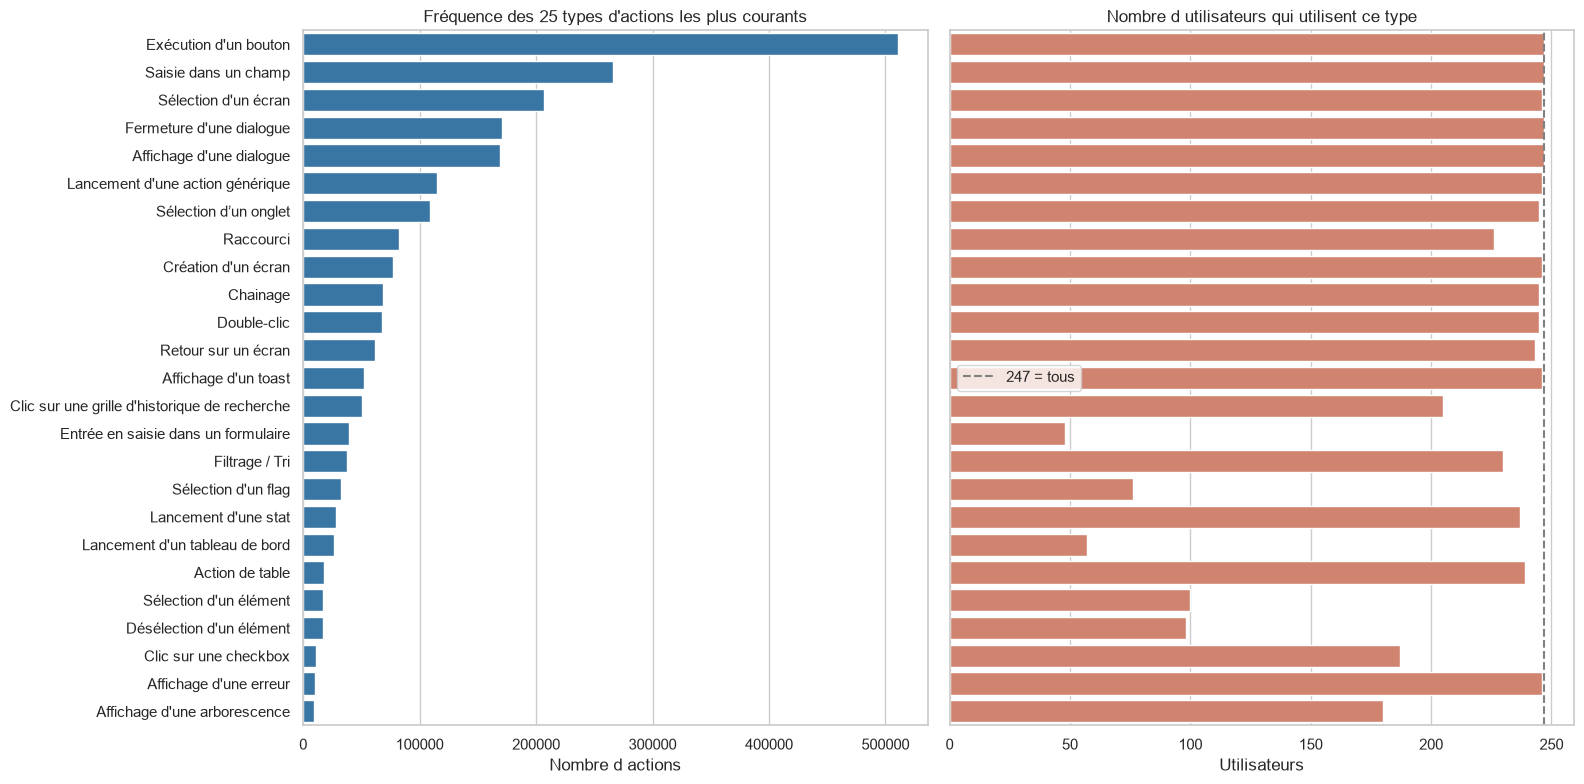

In [21]:
freq_types = evenements['type'].value_counts()
users_par_type = evenements.groupby('type')['util'].nunique()

fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharey=True)
top_types = freq_types.head(25).index

sns.barplot(x=freq_types[top_types].values, y=top_types, ax=axes[0], color='#2878b5')
axes[0].set_title("Fréquence des 25 types d'actions les plus courants")
axes[0].set_xlabel('Nombre d actions')
axes[0].set_ylabel('')

sns.barplot(x=users_par_type[top_types].values, y=top_types, ax=axes[1], color='#e07a5f')
axes[1].axvline(train['util'].nunique(), color='grey', linestyle='--', label='247 = tous')
axes[1].set_title('Nombre d utilisateurs qui utilisent ce type')
axes[1].set_xlabel('Utilisateurs')
axes[1].legend()

plt.tight_layout()
plt.show()

Pour comparer les utilisateurs, on calcule la **proportion** de chaque type dans chaque session (et non le nombre brut, car les sessions ont des longueurs très différentes). La carte de chaleur montre la proportion moyenne pour les 15 utilisateurs qui ont le plus de sessions.

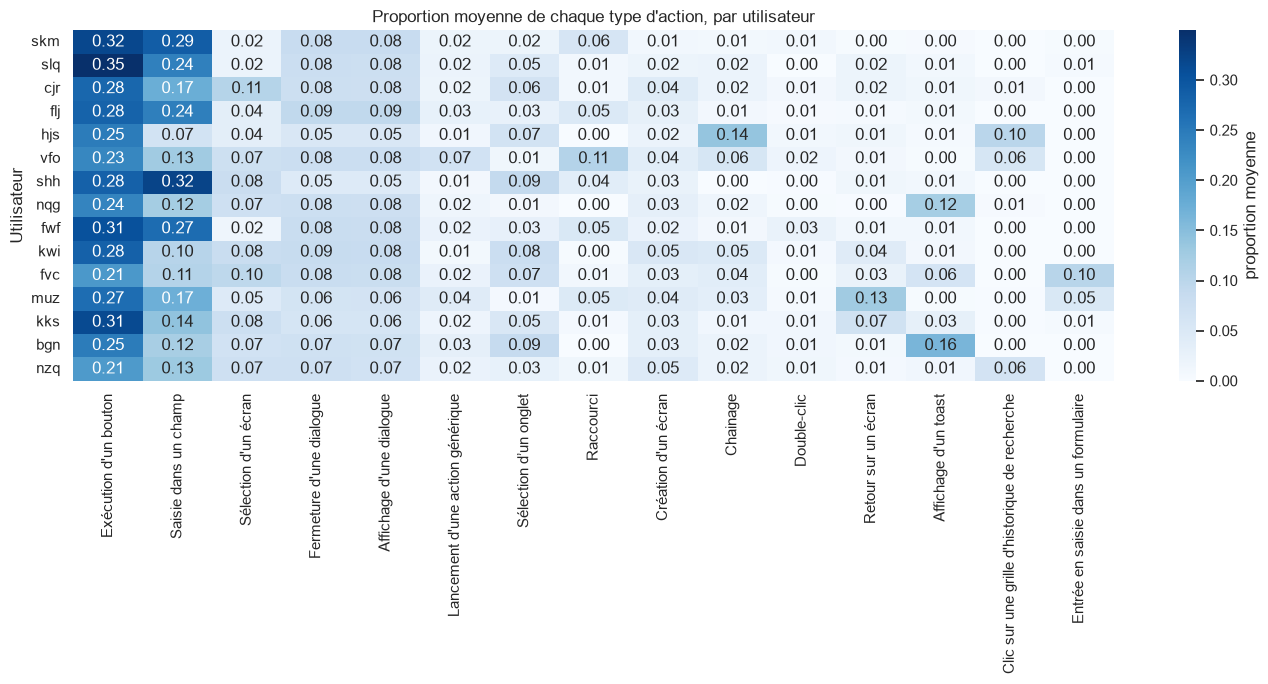

In [22]:
prop_types = pd.crosstab(evenements['session'], evenements['type'], normalize='index')
prop_types['util'] = train.loc[prop_types.index, 'util']

top15 = train['util'].value_counts().head(15).index
profil_types = prop_types[prop_types['util'].isin(top15)].groupby('util')[list(freq_types.head(15).index)].mean()

plt.figure(figsize=(14, 7))
sns.heatmap(profil_types.loc[top15], cmap='Blues', annot=True, fmt='.2f', cbar_kws={'label': 'proportion moyenne'})
plt.title("Proportion moyenne de chaque type d'action, par utilisateur")
plt.xlabel('')
plt.ylabel('Utilisateur')
plt.yticks(rotation=0)  # noms des utilisateurs à l'horizontale
plt.tight_layout()
plt.show()

### 5.3 Écrans, configurations et chaînes

Pour chaque valeur : combien de fois elle apparaît, et **par combien d'utilisateurs différents** elle est utilisée. Une valeur utilisée par un seul utilisateur est une véritable signature.

In [23]:
def frequence_et_utilisateurs(colonne, n=10):
    sous_table = evenements.dropna(subset=[colonne])
    return (sous_table.groupby(colonne)
            .agg(nb_actions=('util', 'size'), nb_utilisateurs=('util', 'nunique'))
            .sort_values('nb_actions', ascending=False))


for colonne in ['ecran', 'conf', 'chaine']:
    table = frequence_et_utilisateurs(colonne)
    uniques = (table['nb_utilisateurs'] == 1).sum()
    print(f'--- {colonne} : {len(table)} valeurs, dont {uniques} utilisées par un seul utilisateur')
    display(table.head(10))

--- ecran : 418 valeurs, dont 147 utilisées par un seul utilisateur


,nb_actions,nb_utilisateurs
ecran,,
MAINT,37932,212
infologic.core.gui.controllers.BlankController,33615,236
infologic.core.FichiersController,18425,232
infologic.crm.modules.CRM_PLANNING.planning.PlanningController,17564,208
DEV,15759,178
infologic.infoc.statmodif.fichierbase.StatFBController,15006,150
infologic.core.gui.controllers.nested.InputFormNestedWindow,9936,240
infologic.orga.modules.OR_FICHIERTRAVAIL.InstanceForm,9907,206
infologic.core.accueil.AccueilController,8484,198


--- conf : 219 valeurs, dont 41 utilisées par un seul utilisateur


,nb_actions,nb_utilisateurs
conf,,
DEF_03/24,18186,202
DEF_07/23,16313,203
STD,10544,241
INSTALLATEUR,9567,108
TELEM_MINIMAL,7595,196
001,4116,162
MT_AppelN1,3092,26
ACCUEIL_INST,2648,90
005,2630,111


--- chaine : 76 valeurs, dont 9 utilisées par un seul utilisateur


,nb_actions,nb_utilisateurs
chaine,,
VT,53480,123
GP,39424,108
EDI,33359,124
TEC,26315,112
OT,24509,162
SV,23681,111
GESCO,22173,111
JCP,21653,77
ST,17160,115


Un utilisateur travaille-t-il toujours sur la même chaîne ? Pour chaque session, on prend la chaîne la plus utilisée, puis on regarde si c'est la chaîne préférée habituelle de l'utilisateur.

Sessions sans aucune chaîne : 32%
Parmi les autres, sessions dont la chaîne principale est la chaîne habituelle de l utilisateur : 66%


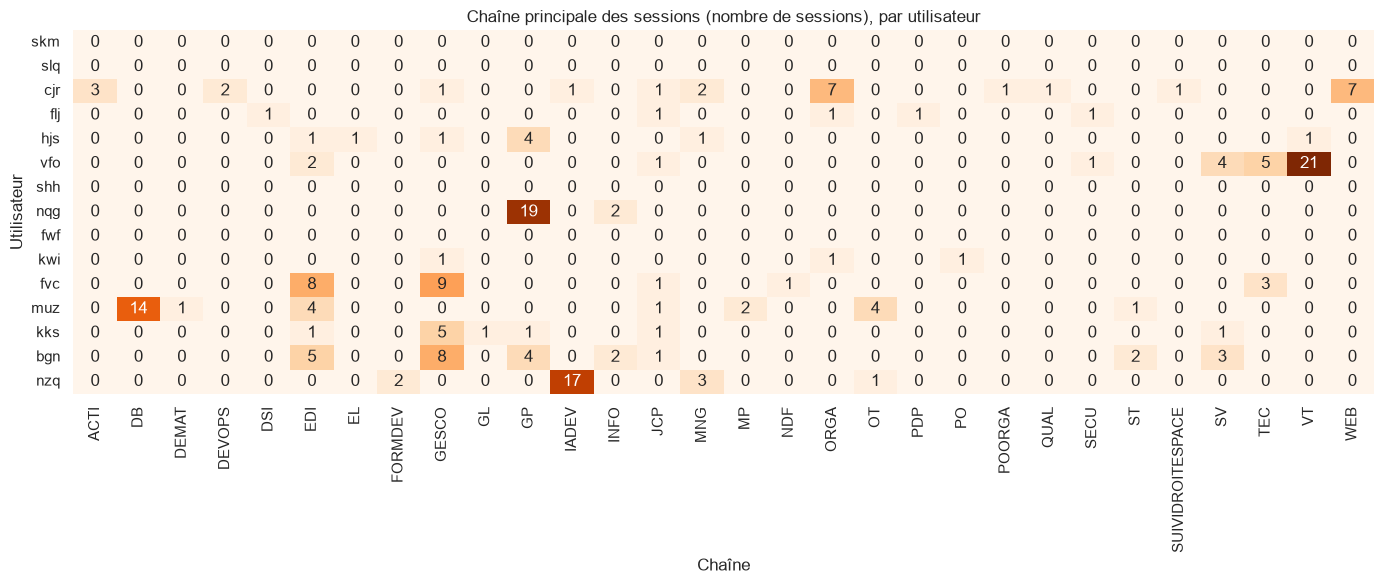

In [24]:
chaine_fav_session = (evenements.dropna(subset=['chaine'])
                      .groupby('session')['chaine'].agg(lambda s: s.value_counts().index[0]))
fav = pd.DataFrame({'chaine_fav': chaine_fav_session, 'util': train.loc[chaine_fav_session.index, 'util']})
chaine_habituelle = fav.groupby('util')['chaine_fav'].agg(lambda s: s.value_counts().index[0])
coherence = (fav['chaine_fav'] == fav['util'].map(chaine_habituelle)).mean()

print(f'Sessions sans aucune chaîne : {1 - len(fav) / len(train):.0%}')
print(f'Parmi les autres, sessions dont la chaîne principale est la chaîne habituelle de l utilisateur : {coherence:.0%}')

# reindex : les utilisateurs qui n'utilisent jamais de chaîne apparaissent avec des 0
chaines_top15 = pd.crosstab(fav['util'], fav['chaine_fav']).reindex(top15, fill_value=0)
chaines_top15 = chaines_top15.loc[:, chaines_top15.sum() > 0]
plt.figure(figsize=(14, 6))
sns.heatmap(chaines_top15, cmap='Oranges', annot=True, fmt='d', cbar=False)
plt.title('Chaîne principale des sessions (nombre de sessions), par utilisateur')
plt.xlabel('Chaîne')
plt.ylabel('Utilisateur')
plt.yticks(rotation=0) 
plt.tight_layout()
plt.show()

## 6. Valeurs manquantes, valeurs aberrantes et cohérence train / test

- **Valeur manquante** : une variable qu'on n'a pas pu calculer pour une session.
- **Valeur aberrante** (*outlier*) : une valeur très éloignée des autres. Elle peut être une erreur (à retirer) ou un comportement réel mais rare (à garder).
- **Cohérence train / test** : les sessions à prédire ressemblent-elles à celles d'entraînement ?

### 6.1 Valeurs manquantes

In [25]:
import numpy as np

colonnes_num = ['nb_actions', 'duree_s', 'actions_par_min',
                'actions_par_fenetre_moy', 'actions_par_fenetre_max', 'actions_par_fenetre_std']

manquants = train[colonnes_num].isna().sum()
display(manquants.to_frame('valeurs manquantes'))

# Quelles sessions sont concernées ?
display(train.loc[train[colonnes_num].isna().any(axis=1), ['util', 'nb_actions', 'duree_s'] + colonnes_num[3:]])

,valeurs manquantes
nb_actions,0
duree_s,0
actions_par_min,0
actions_par_fenetre_moy,1
actions_par_fenetre_max,1
actions_par_fenetre_std,2


,util,nb_actions,duree_s,actions_par_fenetre_moy,actions_par_fenetre_max,actions_par_fenetre_std
1251,fvc,0,15.0,NaN,NaN,NaN
3141,fou,1,5.0,1.0,1.0,NaN


**À retenir :** les données brutes n'ont aucune valeur manquante. Les seuls NaN viennent de **calculs impossibles** sur 2 sessions quasi vides : `fvc` (0 action, donc ni moyenne ni pic) et `fou` (1 seule fenêtre de 5 s, donc pas d'écart-type, qui demande au moins 2 valeurs).

### 6.2 Boxplots des variables numériques

Échelle logarithmique, car les valeurs vont de quelques unités à plusieurs milliers.

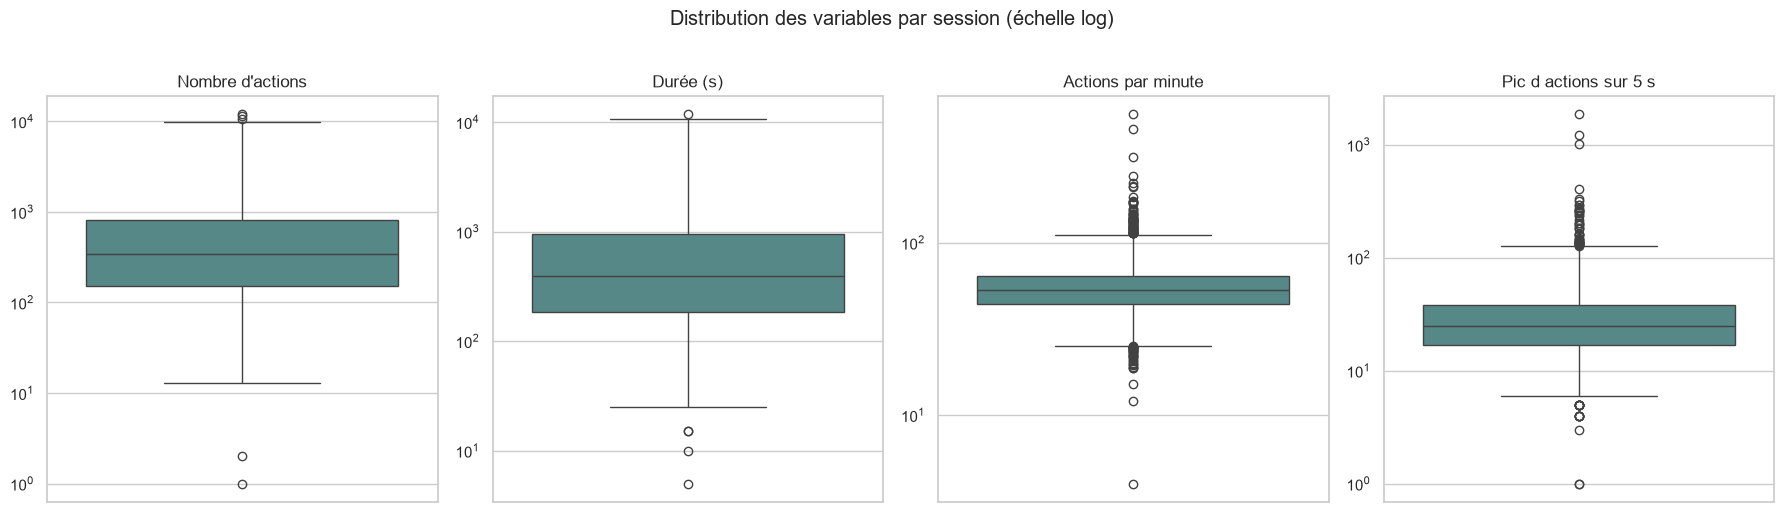

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
variables = ['nb_actions', 'duree_s', 'actions_par_min', 'actions_par_fenetre_max']
titres = ["Nombre d'actions", 'Durée (s)', 'Actions par minute', 'Pic d actions sur 5 s']

for ax, variable, titre in zip(axes, variables, titres):
    sns.boxplot(y=train[variable], ax=ax, color='#4d908e', log_scale=True)
    ax.set_title(titre)
    ax.set_ylabel('')

plt.suptitle('Distribution des variables par session (échelle log)', y=1.02)
plt.tight_layout()
plt.show()

### 6.3 Comptage des valeurs aberrantes

Règle du boxplot (Tukey) : une valeur est aberrante si elle sort de [Q1 − 1,5 × IQR ; Q3 + 1,5 × IQR], où IQR = Q3 − Q1. On l'applique sur l'échelle normale puis sur l'échelle log.

In [27]:
def compter_aberrantes(serie):
    """Règle de Tukey (boxplot) : en dehors de [Q1 - 1,5 x IQR ; Q3 + 1,5 x IQR]."""
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)).sum()


aberrantes = pd.DataFrame({
    'échelle normale': [compter_aberrantes(train[v]) for v in variables],
    'échelle log': [compter_aberrantes(np.log1p(train[v])) for v in variables],
}, index=variables)
display(aberrantes)

,échelle normale,échelle log
nb_actions,297,6
duree_s,256,5
actions_par_min,135,102
actions_par_fenetre_max,157,59


**À retenir :** en échelle normale, près de 300 sessions semblent aberrantes pour le nombre d'actions, mais seulement 6 en échelle log. Les variables de volume et de durée sont très **asymétriques** (beaucoup de sessions courtes, quelques très longues) : les sessions longues ne sont pas des erreurs. On passera ces variables **au log** plutôt que de supprimer des sessions.

### 6.4 Sessions vides ou très courtes

In [28]:
tres_courtes = train[train['nb_actions'] <= 5]
display(tres_courtes[['util', 'navigateur', 'nb_actions', 'duree_s', 'actions']])
print('Sessions restantes pour ces utilisateurs :',
      train[train['util'].isin(tres_courtes['util'])].groupby('util').size().to_dict())

,util,navigateur,nb_actions,duree_s,actions
1251,fvc,Google Chrome,0,15.0,"[t5, t10, t15]"
2684,zus,Firefox,2,30.0,[Création d'un écran(infologic.core.accueil.Ac...
3141,fou,Google Chrome,1,5.0,[Création d'un écran(infologic.core.accueil.Ac...


Sessions restantes pour ces utilisateurs : {'fou': 21, 'fvc': 29, 'zus': 13}


**À retenir :** 3 sessions de 5 actions ou moins (`fvc` 0, `fou` 1, `zus` 2 : simple ouverture de l'écran d'accueil). Elles ne disent rien de la façon de travailler. Leurs utilisateurs gardent 13 à 29 autres sessions et le test n'en contient aucune de ce genre. **Décision : on les retire du train.**

### 6.5 Les rafales : accident ou habitude ?

On compare le plus gros pic d'actions sur 5 s d'une session aux autres sessions du même utilisateur.

In [29]:
rafales = train.sort_values('actions_par_fenetre_max', ascending=False).head(8)
display(rafales[['util', 'nb_actions', 'duree_s', 'actions_par_fenetre_max']])

# Accident ou habitude ? On compare la rafale aux autres sessions du même utilisateur
for util in rafales['util'].unique()[:6]:
    pics = train.loc[train['util'] == util, 'actions_par_fenetre_max'].sort_values(ascending=False)
    print(f"{util} : 3 plus gros pics {pics.head(3).astype(int).tolist()}, "
          f"pic médian de ses sessions {pics.median():.0f}")
print(f"Pic médian sur toutes les sessions : {train['actions_par_fenetre_max'].median():.0f}")

,util,nb_actions,duree_s,actions_par_fenetre_max
1806,opp,6761,2370.0,1859.0
2971,vzc,4083,1725.0,1226.0
694,flj,3025,2700.0,1008.0
2770,oec,4769,3410.0,403.0
234,oec,2854,1970.0,331.0
628,kbf,4027,3455.0,315.0
2814,fxg,8476,7415.0,294.0
1616,cxt,765,435.0,291.0


opp : 3 plus gros pics [1859, 81, 47], pic médian de ses sessions 28
vzc : 3 plus gros pics [1226, 48, 43], pic médian de ses sessions 38
flj : 3 plus gros pics [1008, 257, 58], pic médian de ses sessions 16
oec : 3 plus gros pics [403, 331, 249], pic médian de ses sessions 26
kbf : 3 plus gros pics [315, 32, 31], pic médian de ses sessions 27
fxg : 3 plus gros pics [294, 264, 261], pic médian de ses sessions 261
Pic médian sur toutes les sessions : 25


**À retenir :** deux cas très différents.
- **Accidents isolés** : `opp` (1 859 contre 28 habituellement), `vzc` (1 226 contre 38), `flj` (1 008 contre 16). Ce sont surtout des « Lancement d'une action générique » en cascade, probablement un traitement automatique.
- **Habitude** : `fxg` a des pics autour de 260 dans presque toutes ses sessions. C'est sa signature.

**Décision :** aucune suppression (chaque session compte quand un utilisateur n'en a que 4). On **plafonnera** les valeurs extrêmes au 99e percentile et on passera ces variables au log.

### 6.6 Comparaison train / test

On calcule pour le test les mêmes variables que pour le train, puis on compare médianes et maximums.

In [30]:
test['nb_actions'] = test['actions'].apply(compter_actions)
test = pd.concat([test.drop(columns=temps.columns, errors='ignore'),
                  test['actions'].apply(profil_temporel)], axis=1)
test['actions_par_min'] = test['nb_actions'] / (test['duree_s'].clip(lower=5) / 60)

comparaison = pd.concat({'train': train[variables].describe().T[['50%', 'max']],
                         'test': test[variables].describe().T[['50%', 'max']]}, axis=1)
display(comparaison.round(0))

train            test        
                           50%      max    50%     max
nb_actions               340.0  11977.0  365.0  6203.0
duree_s                  395.0  11790.0  408.0  7110.0
actions_par_min           53.0    556.0   52.0   171.0
actions_par_fenetre_max   25.0   1859.0   25.0   252.0

**À retenir :** les médianes sont presque identiques, le test est représentatif du train. Les rafales extrêmes (1 859) n'existent que dans le train (max 252 dans le test), ce qui confirme qu'il s'agit d'accidents.

### 6.7 Valeurs du test jamais vues dans le train

In [31]:
def valeurs(df, motif):
    return {m for actions in df['actions'] for a in actions for m in motif.findall(a)}


for nom, motif in [('écrans', motif_ecran), ('configurations', motif_conf), ('chaînes', motif_chaine)]:
    vu_train, vu_test = valeurs(train, motif), valeurs(test, motif)
    nouveaux = vu_test - vu_train
    sessions = test['actions'].apply(lambda acts: any(m in nouveaux for a in acts for m in motif.findall(a))).sum()
    print(f'{nom} : {len(vu_test)} valeurs dans le test, {len(nouveaux)} jamais vues dans le train '
          f'({sessions} sessions du test concernées)')

écrans : 219 valeurs dans le test, 8 jamais vues dans le train (7 sessions du test concernées)
configurations : 139 valeurs dans le test, 2 jamais vues dans le train (2 sessions du test concernées)
chaînes : 57 valeurs dans le test, 0 jamais vues dans le train (0 sessions du test concernées)


**À retenir :** 8 écrans (7 sessions) et 2 configurations (2 sessions) du test sont inconnus du train ; aucune chaîne ni aucun type d'action inconnu. Impact faible : il suffira de construire les variables du test avec **la liste des colonnes du train**, les valeurs inconnues seront ignorées.

### 6.8 Bilan des traitements

| Problème | Sessions | Traitement |
|---|---|---|
| Sessions vides ou presque (≤ 5 actions) | 3 | retirées du train |
| Valeurs manquantes (variables calculées) | 2 | disparaissent avec le retrait ci-dessus |
| Asymétrie des variables de volume et de temps | toutes | passage au log |
| Rafales accidentelles | une dizaine | plafonnement au 99e percentile |
| Écrans / configurations inconnus dans le test | 9 | ignorés (colonnes du train) |

Le retrait des sessions très courtes est appliqué ci-dessous dans `train_clean`. Le passage au log et le plafonnement seront faits lors de la construction des variables.

In [32]:
train_clean = train[train['nb_actions'] > 5].copy()

print(f'Sessions retirées : {len(train) - len(train_clean)}')
print(f'train_clean : {len(train_clean)} sessions, {train_clean["util"].nunique()} utilisateurs')
print(f'Valeurs manquantes restantes : {train_clean[colonnes_num].isna().sum().sum()}')

Sessions retirées : 3
train_clean : 3276 sessions, 247 utilisateurs
Valeurs manquantes restantes : 0


## 7. Construction du tableau de variables

Un modèle de classification ne sait pas lire une liste d'actions de longueur variable : il lui faut un **tableau** avec **une ligne par session** et **les mêmes colonnes numériques pour toutes les sessions**.

On transforme donc chaque session en un vecteur de variables, en s'appuyant sur l'exploration :

| Famille | Variables | Pourquoi |
|---|---|---|
| Navigateur | one-hot (1 colonne par navigateur) | chaque utilisateur utilise toujours le même (section 5.1) |
| Volume et temps | log du nombre d'actions, log de la durée, actions/min, rythme par fenêtre de 5 s | ≈ 30 % des écarts expliqués par l'utilisateur (section 4) |
| Types d'actions | **proportion** de chacun des 35 types | signatures très fortes (section 5.2) |
| Suffixe `1` | proportion d'actions avec ce suffixe | ≈ 40 % des écarts expliqués |
| Chaînes | proportion de chaque chaîne + indicateur « aucune chaîne » | spécialistes, polyvalents, sans chaîne (section 5.3) |
| Écrans, configurations | proportion de chaque valeur | les valeurs rares sont des signatures (section 5.3) |

**Règles appliquées :**
- des **proportions** plutôt que des comptages, car les sessions ont des longueurs très différentes ;
- **passage au log** et **plafonnement au 99e percentile** pour les variables asymétriques et les rafales (section 6) ;
- le **vocabulaire** (liste des valeurs qui deviennent des colonnes) et les plafonds sont appris **sur le train uniquement**, puis appliqués tels quels au test : mêmes colonnes, dans le même ordre, et les valeurs inconnues du test sont ignorées.

### 7.1 Vocabulaire appris sur le train

On ne garde que les écrans, configurations et chaînes présents dans **au moins 2 sessions** du train : une valeur vue une seule fois ne permet pas d'apprendre à quel utilisateur elle correspond. Cette cellule parcourt les 2,3 millions d'actions (quelques secondes).

In [33]:
from collections import Counter


def composantes_session(actions):
    """Compte, pour une session, les types / écrans / configurations / chaînes de ses actions."""
    evts = [a for a in actions if not est_repere_temps.fullmatch(a)]
    comptes = {'type': Counter(), 'ecran': Counter(), 'conf': Counter(), 'chaine': Counter()}
    nb_suffixe_1 = 0
    for a in evts:
        comptes['type'][motif_type.split(a)[0].removesuffix('1')] += 1
        comptes['ecran'].update(motif_ecran.findall(a))
        comptes['conf'].update(motif_conf.findall(a))
        comptes['chaine'].update(motif_chaine.findall(a))
        nb_suffixe_1 += a.endswith('1')
    return len(evts), nb_suffixe_1, comptes


def apprendre_vocabulaire(df, min_sessions=2):
    """Liste des valeurs à transformer en colonnes, apprise sur le TRAIN uniquement.

    On garde les écrans / configurations / chaînes présents dans au moins `min_sessions` sessions :
    une valeur vue une seule fois ne permet pas d'apprendre quoi que ce soit.
    """
    presence = {'type': Counter(), 'ecran': Counter(), 'conf': Counter(), 'chaine': Counter()}
    for actions in df['actions']:
        _, _, comptes = composantes_session(actions)
        for famille, compte in comptes.items():
            presence[famille].update(compte.keys())  # présence par session, pas nombre d'actions
    vocab = {famille: sorted(v for v, n in presence[famille].items() if n >= min_sessions)
             for famille in presence}
    vocab['navigateur'] = sorted(df['navigateur'].unique())
    # Plafonds pour les rafales et les vitesses extrêmes (99e percentile du train)
    vocab['plafond_fen_max'] = df['actions_par_fenetre_max'].quantile(0.99)
    vocab['plafond_actions_par_min'] = df['actions_par_min'].quantile(0.99)
    return vocab


vocab = apprendre_vocabulaire(train_clean)
for famille in ['navigateur', 'type', 'ecran', 'conf', 'chaine']:
    print(f'{famille:10s} : {len(vocab[famille])} valeurs retenues')
print(f"Plafond du pic sur 5 s : {vocab['plafond_fen_max']:.0f} actions")
print(f"Plafond des actions par minute : {vocab['plafond_actions_par_min']:.0f}")

navigateur : 4 valeurs retenues
type       : 35 valeurs retenues
ecran      : 303 valeurs retenues
conf       : 198 valeurs retenues
chaine     : 68 valeurs retenues
Plafond du pic sur 5 s : 140 actions
Plafond des actions par minute : 134


### 7.2 Variables d'une session

`variables_session` transforme une session en un dictionnaire `{nom de variable: valeur}`. `construire_variables` l'applique à toutes les sessions d'un DataFrame.

In [34]:
def variables_session(ligne, vocab):
    """Transforme UNE session en un dictionnaire de variables numériques."""
    n, nb_suffixe_1, comptes = composantes_session(ligne['actions'])
    denominateur = max(n, 1)  # évite la division par 0
    v = {}

    # Navigateur : one-hot
    for nav in vocab['navigateur']:
        v[f'nav_{nav}'] = float(ligne['navigateur'] == nav)

    # Volume et temps : passage au log + plafonnement des valeurs extrêmes
    v['log_nb_actions'] = np.log1p(n)
    v['log_duree_s'] = np.log1p(ligne['duree_s'])
    v['actions_par_min'] = min(ligne['actions_par_min'], vocab['plafond_actions_par_min'])
    v['actions_par_fenetre_moy'] = ligne['actions_par_fenetre_moy']
    v['log_actions_par_fenetre_max'] = np.log1p(min(ligne['actions_par_fenetre_max'], vocab['plafond_fen_max']))
    v['actions_par_fenetre_std'] = ligne['actions_par_fenetre_std']

    # Proportions : types, suffixe 1, chaînes, écrans, configurations
    for famille in ['type', 'chaine', 'ecran', 'conf']:
        for valeur in vocab[famille]:
            v[f'{famille}_{valeur}'] = comptes[famille][valeur] / denominateur
    v['prop_suffixe_1'] = nb_suffixe_1 / denominateur
    v['aucune_chaine'] = float(sum(comptes['chaine'].values()) == 0)
    return v


def construire_variables(df, vocab):
    """Tableau de variables : une ligne par session, une colonne par variable."""
    X = pd.DataFrame([variables_session(ligne, vocab) for _, ligne in df.iterrows()], index=df.index)
    return X.fillna(0)  # écart-type non calculable (une seule fenêtre de 5 s) -> 0


# Exemple sur la première session
exemple = variables_session(train_clean.iloc[0], vocab)
print(f'{len(exemple)} variables par session. Quelques-unes :')
for cle in ['nav_Firefox', 'log_nb_actions', 'log_duree_s', 'actions_par_min',
            "type_Exécution d'un bouton", 'chaine_JCP', 'aucune_chaine', 'prop_suffixe_1']:
    print(f'  {cle:30s} = {exemple[cle]:.3f}')

616 variables par session. Quelques-unes :
  nav_Firefox                    = 1.000
  log_nb_actions                 = 7.830
  log_duree_s                    = 7.975
  actions_par_min                = 51.924
  type_Exécution d'un bouton     = 0.278
  chaine_JCP                     = 0.327
  aucune_chaine                  = 0.000
  prop_suffixe_1                 = 0.002


### 7.3 Tableaux du train et du test

`X_train` / `X_test` : les variables. `y_train` : la cible (l'utilisateur). Les sessions du test sont **toutes** conservées.

In [39]:
X_train = construire_variables(train_clean, vocab)
X_test = construire_variables(test, vocab)  # même vocabulaire : mêmes colonnes, dans le même ordre
y_train = train_clean['util']

print(f'X_train : {X_train.shape[0]} sessions x {X_train.shape[1]} variables')
print(f'X_test  : {X_test.shape[0]} sessions x {X_test.shape[1]} variables')
display(X_train.iloc[:5, :12])

X_train : 3276 sessions x 616 variables
X_test  : 324 sessions x 616 variables


,nav_Firefox,nav_Google Chrome,nav_Microsoft Edge,nav_Opera,log_nb_actions,log_duree_s,actions_par_min,actions_par_fenetre_moy,log_actions_par_fenetre_max,actions_par_fenetre_std,type_Action de table,type_Affichage d'un toast
0,1.0,0.0,0.0,0.0,7.830028,7.974533,51.924269,4.319588,3.135494,3.694103,0.004375,0.123707
1,0.0,1.0,0.0,0.0,4.510860,5.442418,23.478261,1.914894,1.945910,1.282487,0.000000,0.011111
2,0.0,0.0,1.0,0.0,6.411818,6.621406,48.640000,4.026490,3.135494,3.771732,0.009868,0.011513
3,1.0,0.0,0.0,0.0,6.787845,7.276556,36.788927,3.055172,3.135494,2.913468,0.007901,0.002257
4,0.0,1.0,0.0,0.0,5.159055,5.620401,37.745455,3.089286,2.772589,2.887445,0.017341,0.005780


### 7.4 Vérifications

In [36]:
familles = X_train.columns.str.extract(r'^(nav|type|chaine|ecran|conf)_', expand=False).fillna('volume / temps / autres')
display(familles.value_counts().rename('nb de colonnes').to_frame())

assert list(X_train.columns) == list(X_test.columns), 'Les colonnes du train et du test diffèrent'
assert len(X_test) == 324, 'Le test doit garder ses 324 sessions'
print('Valeurs manquantes :', int(X_train.isna().sum().sum()), '(train),', int(X_test.isna().sum().sum()), '(test)')
print('Colonnes constantes dans le train :', int((X_train.nunique() <= 1).sum()))

,nb de colonnes
ecran,303
conf,198
chaine,68
type,35
volume / temps / autres,8
nav,4


Valeurs manquantes : 0 (train), 0 (test)
Colonnes constantes dans le train : 0


### 7.5 Encodage de la cible

Comme proposé dans les indications, `pd.Categorical` associe un code numérique à chaque utilisateur. Les catégories (`y_cat.categories`) permettront de retrouver le nom de l'utilisateur à partir du code prédit.

In [37]:
y_cat = pd.Categorical(y_train)
y_train_codes = pd.Series(y_cat.codes, index=y_train.index)
print(f'{len(y_cat.categories)} classes, codées de 0 à {y_train_codes.max()}')
print('Exemple :', dict(zip(y_cat.categories[:5], range(5))))

247 classes, codées de 0 à 246
Exemple : {'aho': 0, 'ajo': 1, 'akx': 2, 'ald': 3, 'ats': 4}


### 7.6 Sauvegarde

On enregistre les tableaux pour la partie 2 (modélisation), qui n'aura pas besoin de refaire tout le calcul.

In [38]:
DOSSIER_PREPARE = RACINE / 'donnees_preparees'
DOSSIER_PREPARE.mkdir(exist_ok=True)

X_train.assign(util=y_train).to_csv(DOSSIER_PREPARE / 'train_variables.csv.gz', index_label='session')
X_test.to_csv(DOSSIER_PREPARE / 'test_variables.csv.gz', index_label='session')
print('Fichiers enregistrés dans', DOSSIER_PREPARE)
for f in sorted(DOSSIER_PREPARE.iterdir()):
    print(f'  {f.name} : {f.stat().st_size / 1e6:.1f} Mo')

Fichiers enregistrés dans c:\Users\accent\Desktop\ECL MOD\ML Introd data science\TP_ML_S9\TP_ML_S9\donnees_preparees
  test_variables.csv.gz : 0.1 Mo
  train_variables.csv.gz : 1.0 Mo


### 7.7 Bilan

- **3 276 sessions × 616 variables** pour le train, **324 × 616** pour le test, aucune valeur manquante.
- Répartition : 303 écrans, 198 configurations, 68 chaînes, 35 types, 4 navigateurs, 8 variables de volume / temps / autres.
- Le tableau est prêt pour la modélisation (partie 2) : séparation train / validation, comparaison de modèles, évaluation.